In [1]:
import pandas as pd
import numpy as np

# Train-test split
from sklearn.model_selection import train_test_split

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Baseline model
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import accuracy_score

In [2]:
# Load cleaned dataset
df = pd.read_csv("../data/processed/cleaned_credit_data.csv")

print("Dataset shape:", df.shape)

Dataset shape: (1345310, 210)


In [3]:
# Separate features and target

X = df.drop("default", axis=1)
y = df["default"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1345310, 209)
Target shape: (1345310,)


In [4]:
# Phase 3 — Step 3.1
# Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

X_train shape: (1076248, 209)
X_test shape: (269062, 209)

Train distribution:
default
0    0.800374
1    0.199626
Name: proportion, dtype: float64

Test distribution:
default
0    0.800373
1    0.199627
Name: proportion, dtype: float64


In [5]:
# Phase 3 — Step 3.2
# Create smaller training sample for baseline model

sample_size = 200000

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=sample_size,
    stratify=y_train,
    random_state=42
)

print("Sample shape:", X_train_sample.shape)

print("\nSample distribution:")
print(y_train_sample.value_counts(normalize=True))

Sample shape: (200000, 209)

Sample distribution:
default
0    0.800375
1    0.199625
Name: proportion, dtype: float64


In [6]:
# Phase 3 — Step 3.2.1
# Feature Scaling

scaler = StandardScaler()

# Fit scaler only on training sample
scaler.fit(X_train_sample)

# Transform datasets
X_train_sample_scaled = scaler.transform(X_train_sample)

X_test_scaled = scaler.transform(X_test)

In [7]:
# Phase 3 — Step 3.2.2
# Initialize baseline logistic regression model

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [8]:
# Phase 3 — Step 3.2.3
# Train baseline model

baseline_model.fit(X_train_sample_scaled, y_train_sample)

print("Baseline model training completed")

Baseline model training completed


In [9]:
# Phase 3 — Step 3.2.4
# Predictions

y_train_pred = baseline_model.predict(X_train_sample_scaled)

y_test_pred = baseline_model.predict(X_test_scaled)

In [10]:
# Phase 3 — Step 3.2.5
# Accuracy evaluation

train_accuracy = accuracy_score(y_train_sample, y_train_pred)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Train Accuracy: 0.910785
Test Accuracy: 0.9110836907478573


In [11]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# ROC-AUC score
y_test_prob = baseline_model.predict_proba(X_test_scaled)[:,1]

roc_auc = roc_auc_score(y_test, y_test_prob)

print("\nROC-AUC Score:", roc_auc)

Confusion Matrix:
[[205645   9705]
 [ 14219  39493]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95    215350
           1       0.80      0.74      0.77     53712

    accuracy                           0.91    269062
   macro avg       0.87      0.85      0.86    269062
weighted avg       0.91      0.91      0.91    269062


ROC-AUC Score: 0.9501583062266269


In [12]:
from sklearn.linear_model import LogisticRegression

In [13]:
weighted_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

In [14]:
weighted_model.fit(X_train_sample, y_train_sample)

E:\Skill Sphere\Artificial Intelligence\Projects\loan-risk-system\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
E:\Skill Sphere\Artificial Intelligence\Projects\loan-risk-system\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [15]:
y_pred_weighted = weighted_model.predict(X_test)
y_proba_weighted = weighted_model.predict_proba(X_test)[:,1]

In [17]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

In [18]:
cm_weighted = confusion_matrix(y_test, y_pred_weighted)
print("Confusion Matrix:")
print(cm_weighted)

Confusion Matrix:
[[191065  24285]
 [  7413  46299]]


In [19]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted))


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.89      0.92    215350
           1       0.66      0.86      0.74     53712

    accuracy                           0.88    269062
   macro avg       0.81      0.87      0.83    269062
weighted avg       0.90      0.88      0.89    269062



In [20]:
roc_auc_weighted = roc_auc_score(y_test, y_proba_weighted)

print("\nROC-AUC Score:", roc_auc_weighted)


ROC-AUC Score: 0.9380887046006324


In [21]:
# Default probability
y_proba = weighted_model.predict_proba(X_test)[:,1]

In [22]:
import numpy as np

def apply_threshold(proba, threshold):
    return (proba >= threshold).astype(int)

In [23]:
thresholds = [0.5, 0.45, 0.40, 0.35, 0.30]

for t in thresholds:

    y_pred_t = apply_threshold(y_proba, t)

    cm = confusion_matrix(y_test, y_pred_t)
    report = classification_report(y_test, y_pred_t, output_dict=True)

    recall_default = report["1"]["recall"]
    precision_default = report["1"]["precision"]

    print(f"\nThreshold: {t}")
    print("Recall (Default):", round(recall_default,3))
    print("Precision (Default):", round(precision_default,3))
    print("Confusion Matrix:")
    print(cm)


Threshold: 0.5
Recall (Default): 0.862
Precision (Default): 0.656
Confusion Matrix:
[[191065  24285]
 [  7413  46299]]

Threshold: 0.45
Recall (Default): 0.884
Precision (Default): 0.629
Confusion Matrix:
[[187347  28003]
 [  6237  47475]]

Threshold: 0.4
Recall (Default): 0.903
Precision (Default): 0.6
Confusion Matrix:
[[182938  32412]
 [  5188  48524]]

Threshold: 0.35
Recall (Default): 0.921
Precision (Default): 0.565
Confusion Matrix:
[[177293  38057]
 [  4262  49450]]

Threshold: 0.3
Recall (Default): 0.937
Precision (Default): 0.528
Confusion Matrix:
[[170288  45062]
 [  3394  50318]]


In [24]:
# Final chosen threshold
BEST_THRESHOLD = 0.40

In [25]:
final_predictions = (y_proba >= BEST_THRESHOLD).astype(int)

In [26]:
print("Final Model Evaluation (Threshold = 0.40)\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

Final Model Evaluation (Threshold = 0.40)

Confusion Matrix:
[[182938  32412]
 [  5188  48524]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.85      0.91    215350
           1       0.60      0.90      0.72     53712

    accuracy                           0.86    269062
   macro avg       0.79      0.88      0.81    269062
weighted avg       0.90      0.86      0.87    269062



In [27]:
!pip install xgboost


[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
# =========================================================
# 3.4 Advanced Models
# =========================================================

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [29]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train_sample, y_train_sample)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [30]:
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.9156997272004223

Confusion Matrix:
[[208370   6980]
 [ 15702  38010]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95    215350
           1       0.84      0.71      0.77     53712

    accuracy                           0.92    269062
   macro avg       0.89      0.84      0.86    269062
weighted avg       0.91      0.92      0.91    269062



In [31]:
rf_proba = rf_model.predict_proba(X_test)[:,1]

print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_proba))

Random Forest ROC-AUC: 0.9513139362603529


In [33]:
# Clean column names for XGBoost compatibility

import re

def clean_column_names(columns):
    cleaned = []
    for col in columns:
        col = re.sub(r"[^\w]", "_", col)  # replace special characters with _
        cleaned.append(col)
    return cleaned

X_train_sample.columns = clean_column_names(X_train_sample.columns)
X_test.columns = clean_column_names(X_test.columns)

print("Column names cleaned for XGBoost.")

Column names cleaned for XGBoost.


In [34]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train_sample, y_train_sample)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [35]:
xgb_pred = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

XGBoost Accuracy: 0.9330303052827973

Confusion Matrix:
[[207762   7588]
 [ 10431  43281]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96    215350
           1       0.85      0.81      0.83     53712

    accuracy                           0.93    269062
   macro avg       0.90      0.89      0.89    269062
weighted avg       0.93      0.93      0.93    269062



In [36]:
xgb_proba = xgb_model.predict_proba(X_test)[:,1]

print("XGBoost ROC-AUC:", roc_auc_score(y_test, xgb_proba))

XGBoost ROC-AUC: 0.969607585769548


In [37]:
# Feature Importance from XGBoost

import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train_sample.columns,
    "importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance.head(20)

,feature,importance
20,last_fico_range_low,0.245057
85,mths_since_rcnt_il_missing_flag,0.175741
19,last_fico_range_high,0.137146
3,term,0.032770
88,months_since_last_credit_pull,0.013772
86,loan_age_months,0.009459
2,funded_amnt_inv,0.008317
32,mths_since_rcnt_il,0.007780
0,loan_amnt,0.006241
29,open_act_il,0.005434


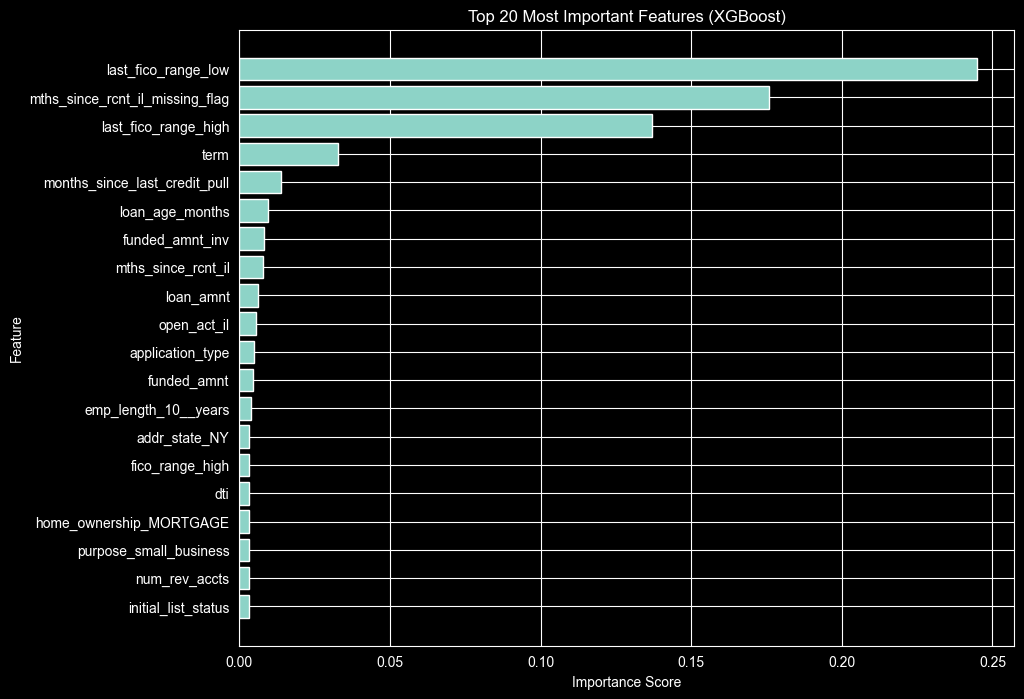

In [38]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20)

plt.figure(figsize=(10,8))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()

plt.title("Top 20 Most Important Features (XGBoost)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

In [39]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

param_grid = {
    "n_estimators": [200, 300, 400],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "gamma": [0, 0.1, 0.2]
}

xgb = XGBClassifier(
    eval_metric="logloss",
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_sample, y_train_sample)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [4, 6, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here..

In [40]:
best_xgb = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

Best Parameters:
{'subsample': 0.7, 'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.2, 'colsample_bytree': 0.7}


In [41]:
y_pred = best_xgb.predict(X_test)
y_prob = best_xgb.predict_proba(X_test)[:,1]

from sklearn.metrics import accuracy_score, roc_auc_score

print("Tuned XGBoost Accuracy:", accuracy_score(y_test, y_pred))
print("Tuned XGBoost ROC-AUC:", roc_auc_score(y_test, y_prob))

Tuned XGBoost Accuracy: 0.9325620117296385
Tuned XGBoost ROC-AUC: 0.9697245612282352


In [42]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        0.911,
        0.916,
        0.933
    ],
    "ROC_AUC": [
        0.950,
        0.951,
        0.9697
    ]
})

model_results

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.911,0.9500
1,Random Forest,0.916,0.9510
2,XGBoost,0.933,0.9697


In [43]:
final_model = best_xgb

In [44]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(final_model, "../models/credit_risk_xgboost_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [45]:
loaded_model = joblib.load("../models/credit_risk_xgboost_model.pkl")

print("Model loaded successfully")

Model loaded successfully


In [46]:
sample_data = X_test.iloc[:5]

predictions = loaded_model.predict(sample_data)

print("Predictions:", predictions)

Predictions: [0 0 0 0 0]


In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importances = best_xgb.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print(feature_importance.head(15))

                             Feature  Importance
20               last_fico_range_low    0.252555
19              last_fico_range_high    0.129096
85   mths_since_rcnt_il_missing_flag    0.077877
3                               term    0.034798
88     months_since_last_credit_pull    0.018069
4                           int_rate    0.012002
86                   loan_age_months    0.010722
32                mths_since_rcnt_il    0.010535
2                    funded_amnt_inv    0.006753
1                        funded_amnt    0.006568
0                          loan_amnt    0.005907
24                  application_type    0.005589
29                       open_act_il    0.005545
10                   fico_range_high    0.004146
156           purpose_small_business    0.003998


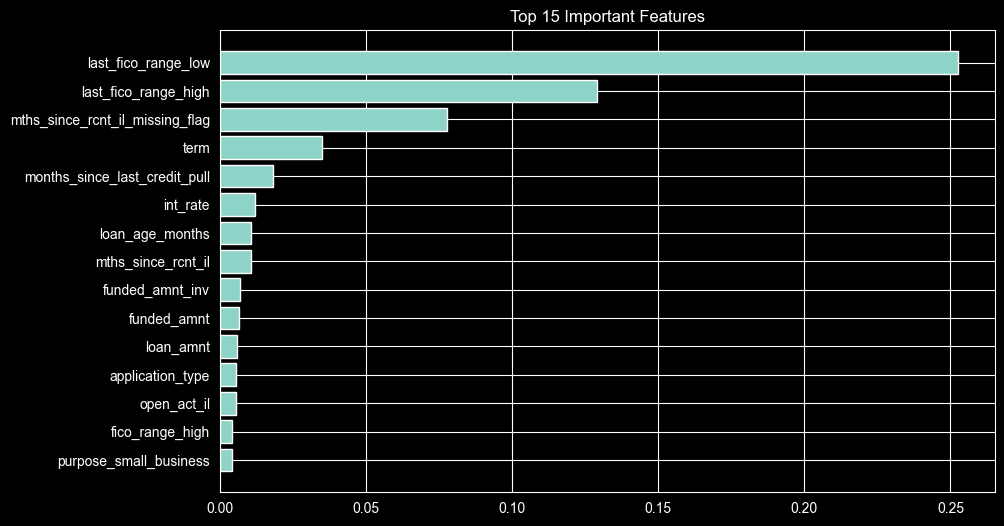

In [48]:
plt.figure(figsize=(10,6))
plt.barh(feature_importance["Feature"][:15], feature_importance["Importance"][:15])
plt.gca().invert_yaxis()
plt.title("Top 15 Important Features")
plt.show()

In [49]:
pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
import shap

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

E:\Skill Sphere\Artificial Intelligence\Projects\loan-risk-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


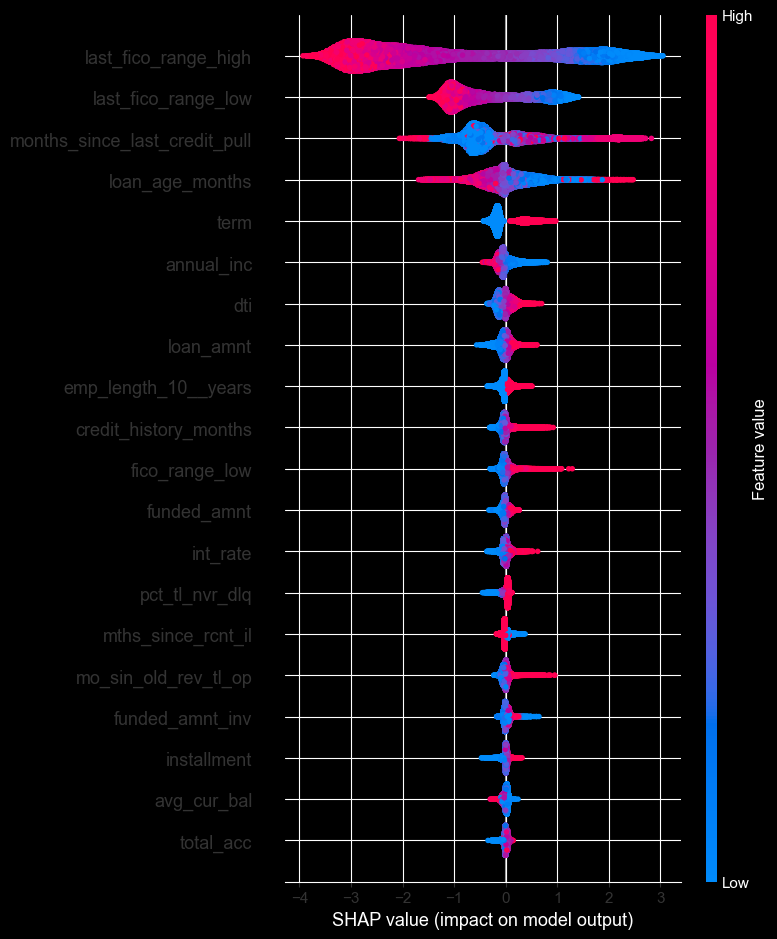

In [51]:
shap.summary_plot(shap_values, X_test)

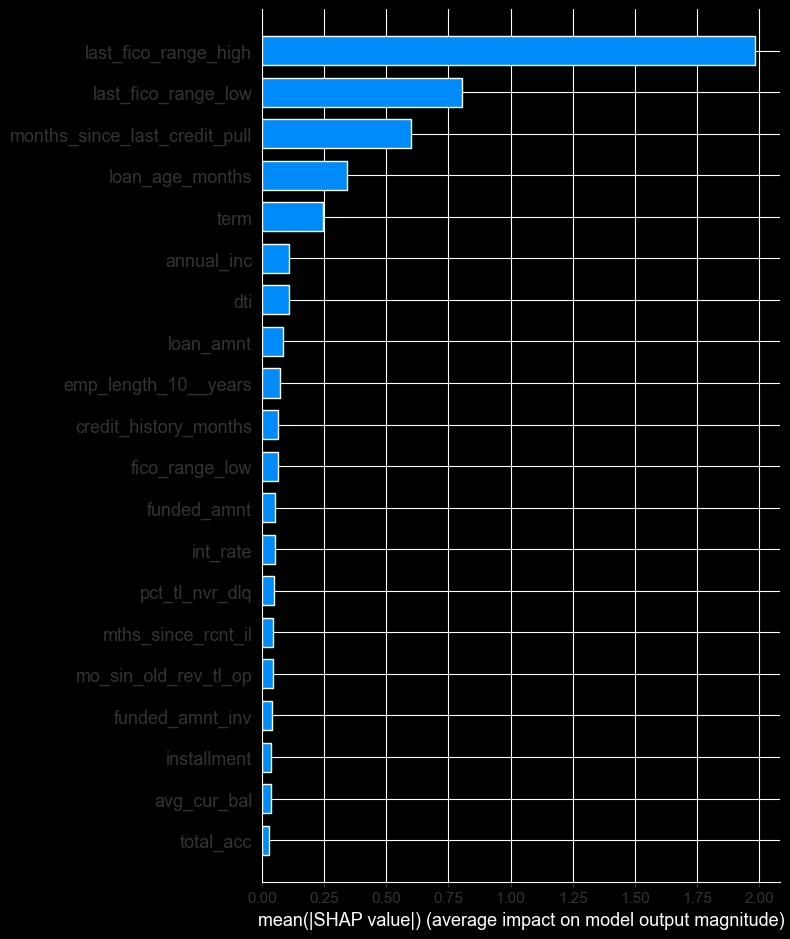

In [52]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [53]:
sample = X_test.iloc[0]

shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    sample
)

In [54]:
import joblib

joblib.dump(best_xgb, "../models/credit_risk_model.pkl")

['credit_risk_model.pkl']

In [55]:
joblib.dump(X_train.columns, "../models/model_features.pkl")

['model_features.pkl']